In [40]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.stats.weightstats import ztest

df = pd.read_csv('Mall_Customers.csv')
alpha = 0.05

male_inc = df[df['Genre'] == 'Male']['Annual Income (k$)']
female_inc = df[df['Genre'] == 'Female']['Annual Income (k$)']

male_age = df[df['Genre'] == 'Male']['Age']
female_age = df[df['Genre'] == 'Female']['Age']

spend = df['Spending Score (1-100)']

1. Проверьте утверждение, что « Мужчины и женщины 50% своего дохода тратят в  супермаркетах»

In [23]:
# рассчет с помощью таблицы 

n = len(spend)
mu = spend.mean()
sigma = spend.std()
mu_0 = 50

z_obs = (mu - mu_0) / (sigma / np.sqrt(n))
z_crit = stats.norm.ppf(1 - alpha / 2)

print(f"Z_набл = {z_obs:.3f}, Z_крит = {z_crit:.3f}")

Z_набл = 0.110, Z_крит = 1.960


In [24]:
# рассчет с помощью statsmodels

z_obs_st, p_val_st = ztest(spend, value=50)

print(f"Z_набл = {z_obs_st:.3f}, p-value: {p_val_st:.3f}")

Z_набл = 0.110, p-value: 0.913


2. Проверьте утверждение, что «Доход у мужчин больше, чем у женщин» с уровнем значимости 5%

In [45]:
mu_1, mu_2 = male_inc.mean(), female_inc.mean()

sigma_1, sigma_2 = male_inc.std(), female_inc.std()
#print(f"дисперсия мужчины: {sigma_1:.3f}, дисперсия женщины {sigma_2:.3f}\n")

n_1, n_2 = len(male_inc), len(female_inc)

z_obs = (mu_1 - mu_2) / np.sqrt(sigma_1 ** 2 / n_1 + sigma_2 ** 2 / n_2)
z_crit_2 = stats.norm.ppf(1 - alpha) 

print(f"Z_набл = {z_obs:.3f}, Z_крит = {z_crit_2:.3f}")

Z_набл = 0.793, Z_крит = 1.645


In [26]:
z_obs_st_2, p_val_st_2 = ztest(male_inc, female_inc, alternative='larger')

print(f"Z_набл = {z_obs_st_2:.3f}, p-value: {p_val_st_2:.3f}")

Z_набл = 0.795, p-value: 0.213


3. Одинакова ли дисперсия возраста? (F-критерий)

In [ ]:
var_1, var_2 = male_age.var(), female_age.var()

f_obs = var_1 / var_2 if var_1 > var_2 else var_2 / var_1

dg_fr_1, dg_fr_2 = len(male_age) - 1, len(female_age) - 1


f_crit = stats.f.ppf(1 - alpha / 2, dg_fr_1, dg_fr_2)

print(f"F_набл = {f_obs:.3f}, F_крит = {f_crit:.3f}")

F_набл = 1.506, F_крит = 1.483


In [28]:
stat_lev, p_lev = stats.levene(male_age, female_age)

print(f"p-value: {p_lev:.3f}")

p-value: 0.037


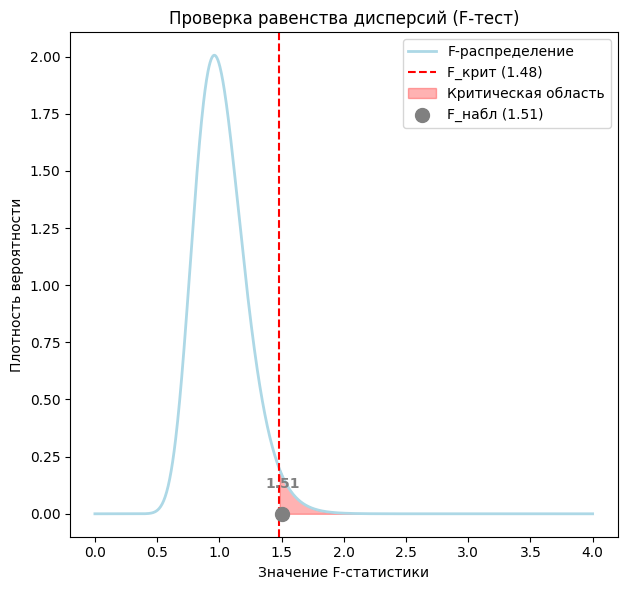

In [29]:
x = np.linspace(0, 4, 1000) # значения F
y = stats.f.pdf(x, dg_fr_1, dg_fr_2) # плотность распределения Фишера

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(x, y, label='F-распределение', color='lightblue', lw=2)

plt.axvline(f_crit, color='red', linestyle='--', label=f'F_крит ({f_crit:.2f})')
plt.fill_between(x, 0, y, where=(x > f_crit), color='red', alpha=0.3, label='Критическая область')

plt.scatter([f_obs], [0], color='grey', s=100, zorder=5, label=f'F_набл ({f_obs:.2f})')
plt.annotate(f'{f_obs:.2f}', (f_obs, 0.05), textcoords="offset points", xytext=(0,10), ha='center', color='grey', weight='bold')

plt.title('Проверка равенства дисперсий (F-тест)')
plt.xlabel('Значение F-статистики')
plt.ylabel('Плотность вероятности')
plt.legend()

plt.tight_layout()
plt.show()

Срок эксплуатации турбореактивного двигателя (характеристика надежности) определяется как сумма сроков службы его лопаток. 
Предполагая, что срок службы ti каждой из N = 100 лопаток описывается экспоненциальным законом с параметром интенсивности выхода из строя, равном λ = 2. Все ti  являются независимыми.

Какой закон распределения будет иметь надежность всего двигателя? Обоснуйте вывод.
Убедитесь в правильности ответа. 

1) Постройте переменную T (для генерации выборки t_i можно использовать произвольное количество элементов, но желательно больше 100).

In [30]:
N = 100
lamb = 2

mu_theory = 50  # (1 / lambda) * N
var_theory = 25  # (1 / lambda ^ 2) * N

T_samples = np.random.exponential(1 / lamb, size=(1000, N)).sum(axis=1)

2) Вычислите параметры предполагаемого закона распределения T и сравните их с теоретическими.

In [31]:
mean_emp = np.mean(T_samples)
var_emp = np.var(T_samples)

print(f"Теоретическое M[T]: {mu_theory:.3f}, Вычисленное M[T]: {mean_emp:.3f}")
print(f"Теоретическое D[T]: {var_theory:.3f}, Вычисленная D[T]: {var_emp:.3f}")

Теоретическое M[T]: 50.000, Вычисленное M[T]: 49.925
Теоретическое D[T]: 25.000, Вычисленная D[T]: 23.840


3) Постройте гистограммы относительных частот и эмпирическую функцию распределения для T.

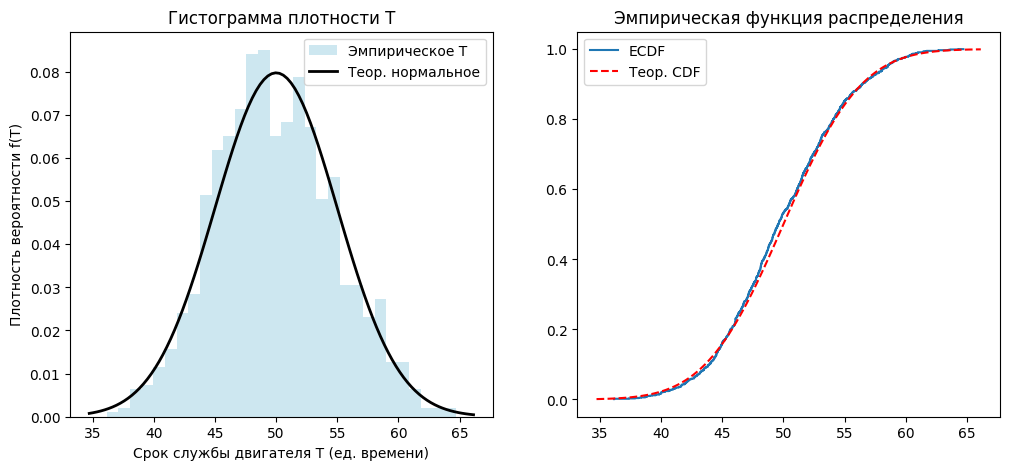

In [32]:
plt.figure(figsize=(12, 5))

# Гистограмма частот
plt.subplot(1, 2, 1)
plt.hist(T_samples, bins=30, density=True, alpha=0.6, color='lightblue', label='Эмпирическое T')

# Теоретическая кривая нормального распределения
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, 50, 5)
plt.plot(x, p, 'k', linewidth=2, label='Теор. нормальное')
plt.title('Гистограмма плотности T')
plt.xlabel('Срок службы двигателя T (ед. времени)') # случайные величины
plt.ylabel('Плотность вероятности f(T)')
plt.legend()

# Эмпирическая функция распределения (ECDF)
plt.subplot(1, 2, 2)
sorted_T = np.sort(T_samples)
y = np.arange(1, len(sorted_T) + 1) / len(sorted_T)
plt.step(sorted_T, y, label='ECDF')

# Теоретическая CDF
plt.plot(x, stats.norm.cdf(x, 50, 5), 'r--', label='Теор. CDF')
plt.title('Эмпирическая функция распределения')
plt.legend()
plt.show()

4) Проверьте гипотезу о предполагаемом виде закона распределения.

Основываясь на ЦП, т.к. N = 100, было сделано предположение, что надежность всего двигателя будет иметь нормальное распределдение. Для проверки гипотезы будет использован критерий Хи-квадрата.

In [39]:
sigma_theory = np.sqrt(var_theory)
n = len(T_samples)

m = int(3.78 * (n - 1) ** (2 / 5))
print(f"Количество интервалов: {m}\n")

# относительные частоты n_i
counts, bins = np.histogram(T_samples, bins=m)

# теоретические вероятности попадания в интервал
p_i = np.diff(stats.norm.cdf(bins, loc=mu_theory, scale=sigma_theory))

p_i[0] = stats.norm.cdf(bins[1], loc=mu_theory, scale=sigma_theory)  # захват площади от - бесконечности
p_i[-1] = 1 - stats.norm.cdf(bins[-2], loc=mu_theory, scale=sigma_theory)  # захват площади от пердполседнего интервала до + бесконечности

counts_theory = p_i * n

# наблюдаемое значение Хи-квадат и вероятность случайности
#chi_stat, p_val = stats.chisquare(f_obs=counts, f_exp=counts_theory, ddof=2)

alpha = 0.05

chi_stat = np.sum((counts - counts_theory) ** 2 / counts_theory)

chi_crit = stats.chi2.ppf(1 - alpha, df=m-2-1)

print(f"Хи-квадрат наблюдаемое: {chi_stat:.4f}")
print(f"Хи-квадрат критическое: {chi_crit:.4f}\n")


if chi_stat < chi_crit:
    print(f"Так как Хи-квадрат < {chi_crit:.4f}, гипотеза H0 о нормальном законе принимается")
else:
    print(f"Так как Хи-квадрат >= {chi_crit}, гипотеза H0 отвергается")

Количество интервалов: 59

Хи-квадрат наблюдаемое: 55.1755
Хи-квадрат критическое: 74.4683

Так как Хи-квадрат < 74.4683, гипотеза H0 о нормальном законе принимается
